# Global Deforestation Analysis (1990–2025)
## Notebook 02: Exploratory Data Analysis (EDA)

### Purpose & Research Objectives
This notebook conducts comprehensive exploratory statistical analysis across national and continental forest datasets. We explore:
1. Parametric and non-parametric distributions of forest cover and deforestation rates.
2. Inter-decadal transitions (1990s, 2000s, 2010s, 2020s).
3. Continental variance and disparities in forest loss and recovery.
4. Correlation matrices between forest changes, land area, and carbon emissions.


In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJ_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(PROJ_ROOT)
from src.utils import load_processed_data, THEME

data = load_processed_data()
df_panel = data["country_panel"]
df_global = data["global_summary"]
df_hotspots = data["hotspots"]

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["figure.dpi"] = 120
print("Datasets loaded successfully.")


Datasets loaded successfully.


### 1. Summary Statistics & Distribution of Country Forest Areas
We examine skewness and kurtosis of national forest holdings in 2020. Forest area is highly skewed: a small number of megadiverse, geographically extensive nations (Russia, Brazil, Canada, USA, China, DRC) hold over 50% of the Earth's forest biomass.


In [2]:
df_2020 = df_panel[df_panel["Year"] == 2020]
stats_2020 = df_2020[["Forest_Area_Mha", "Forest_Share_pct", "Annual_Change_Mha", "CO2_Emissions_Mt"]].describe().T
stats_2020["skewness"] = df_2020[["Forest_Area_Mha", "Forest_Share_pct", "Annual_Change_Mha", "CO2_Emissions_Mt"]].skew()
stats_2020


,count,mean,std,min,25%,50%,75%,max,skewness
Forest_Area_Mha,235.0,17.724422,72.865300,0.000000,0.032730,1.257860,8.024515,828.432200,8.097035
Forest_Share_pct,215.0,32.987551,24.864162,0.000000,11.680333,32.788826,52.224968,95.803505,0.460884
Annual_Change_Mha,235.0,-0.013782,0.231480,-2.628413,-0.003828,0.000000,0.000653,1.760750,-3.955019
CO2_Emissions_Mt,197.0,26.579929,121.722087,-263.683470,-0.035541,1.177830,12.582323,1369.239600,8.124901


### 2. Distribution Visualization: Histogram & Boxplots
Visualizing the distribution of forest share percentage and net annual change across countries.


C:\Users\i-genie techoholics\AppData\Local\Temp\ipykernel_9672\2049898543.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_2020["Continent"], y=df_2020["Annual_Change_Mha"], ax=axes[1], palette="Set2")


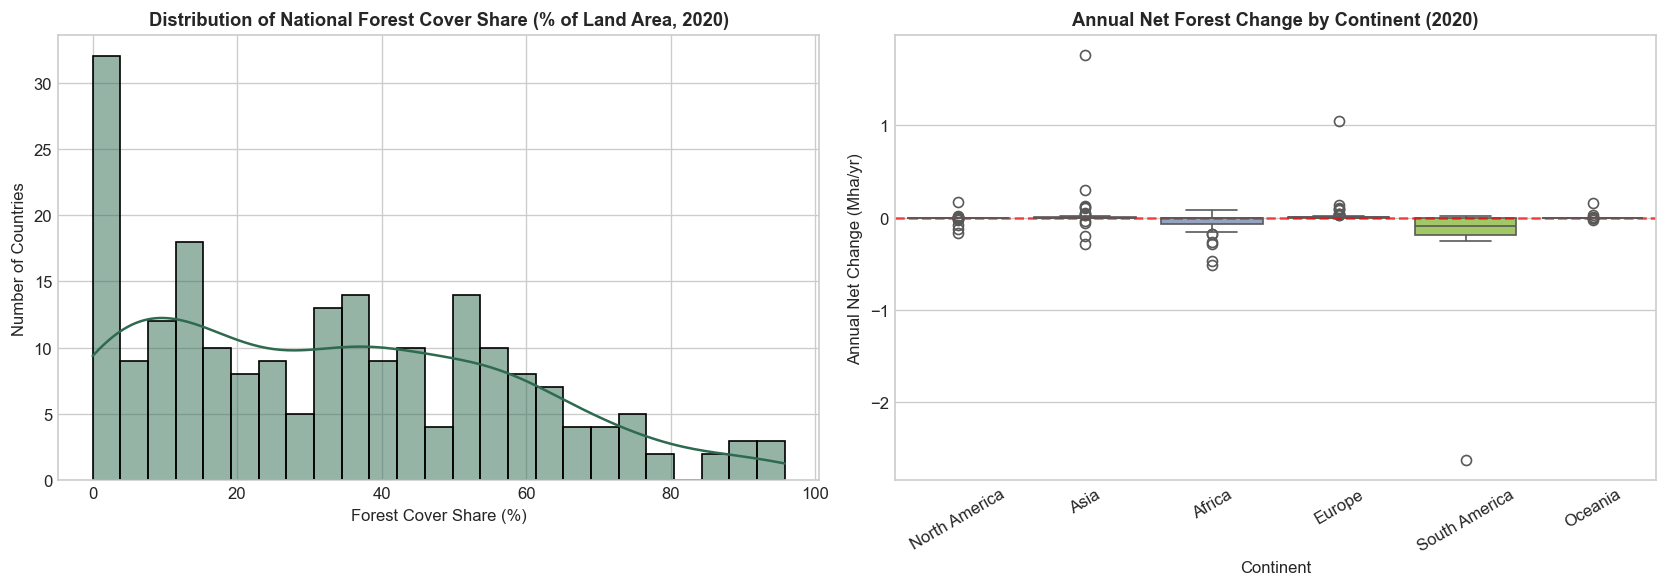

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of Forest Cover Share (%)
sns.histplot(df_2020["Forest_Share_pct"].dropna(), bins=25, kde=True, ax=axes[0], color="#2d6a4f")
axes[0].set_title("Distribution of National Forest Cover Share (% of Land Area, 2020)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Forest Cover Share (%)")
axes[0].set_ylabel("Number of Countries")

# Distribution of Annual Net Change (Mha/yr)
sns.boxplot(x=df_2020["Continent"], y=df_2020["Annual_Change_Mha"], ax=axes[1], palette="Set2")
axes[1].axhline(0, color="red", linestyle="--", alpha=0.7)
axes[1].set_title("Annual Net Forest Change by Continent (2020)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Continent")
axes[1].set_ylabel("Annual Net Change (Mha/yr)")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### 3. Decadal Comparison (1990s vs 2000s vs 2010s vs 2020s)
We classify years into four distinct decades to measure whether national and global deforestation has decelerated:
- **1990–1999**: Post-Cold War baseline & early tropical clearing surge.
- **2000–2009**: Peak Amazon and Southeast Asian commercial conversion.
- **2010–2019**: Early REDD+ interventions, Brazilian moratoriums, and Indonesian moratoriums.
- **2020–2025**: Recent dynamics, COVID-19 pandemic disruptions, Glasgow declaration.


In [4]:
def assign_decade(yr):
    if yr < 2000:
        return "1990s"
    elif yr < 2010:
        return "2000s"
    elif yr < 2020:
        return "2010s"
    else:
        return "2020s"
        
df_panel["Decade"] = df_panel["Year"].apply(assign_decade)
decade_summary = df_panel.groupby(["Decade", "Continent"])["Annual_Change_Mha"].sum().unstack()
decade_summary


Continent,Africa,Asia,Europe,North America,Oceania,South America
Decade,,,,,,
1990s,-29.500747,-3.839480,7.383477,-3.020286,-1.228760,-66.046790
2000s,-33.753476,24.433049,14.021786,6.376815,-1.874399,-51.925937
2010s,-36.346511,19.307174,12.229954,3.095023,1.829360,-36.194750
2020s,-17.305038,8.127628,7.519418,-1.688935,0.756389,-25.672881


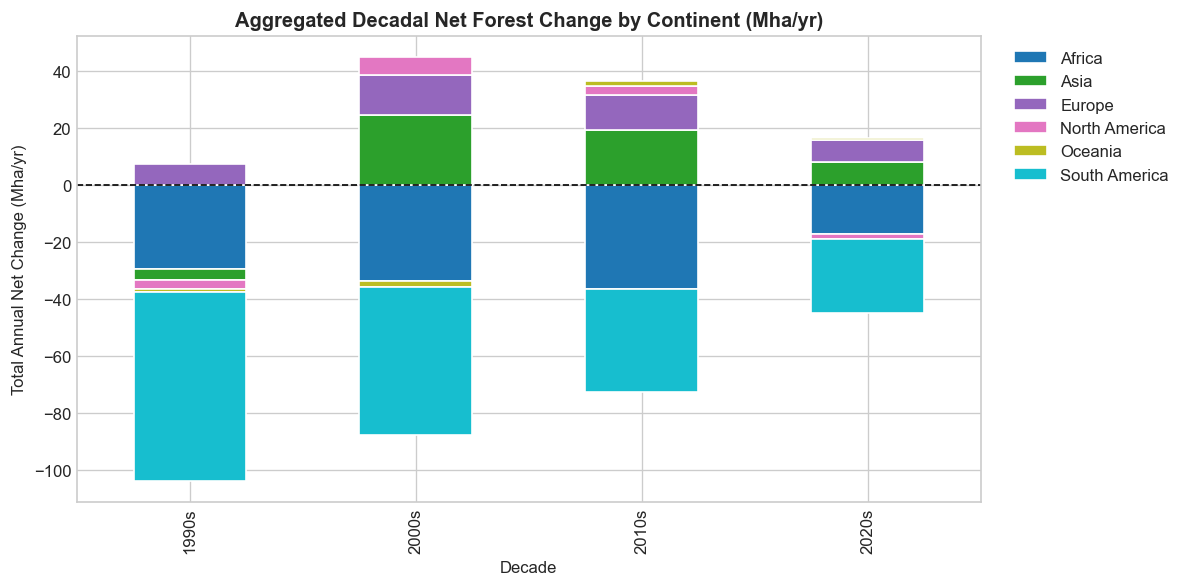

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
decade_summary.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", edgecolor="white")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Aggregated Decadal Net Forest Change by Continent (Mha/yr)", fontsize=12, fontweight="bold")
ax.set_ylabel("Total Annual Net Change (Mha/yr)")
ax.set_xlabel("Decade")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### 4. Correlation Analysis
We compute Spearman rank correlation coefficients between forest metrics, land area, and carbon emissions.


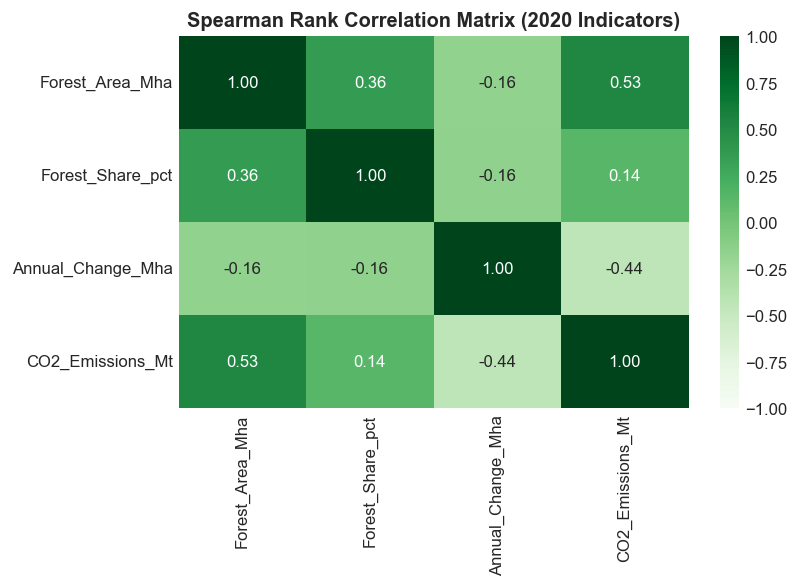

In [6]:
corr_cols = ["Forest_Area_Mha", "Forest_Share_pct", "Annual_Change_Mha", "CO2_Emissions_Mt"]
corr_mat = df_2020[corr_cols].corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(corr_mat, annot=True, cmap="Greens", vmin=-1, vmax=1, fmt=".2f", cbar=True)
plt.title("Spearman Rank Correlation Matrix (2020 Indicators)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Statistical Findings & EDA Conclusions
1. **Severe Regional Bipolarity**: South America and Africa consistently exhibit large negative net forest changes across all decades, driven by agricultural expansion.
2. **Temperate Net Gain**: Europe and Asia (predominantly China) show sustained net positive forest gains due to extensive afforestation programs and natural abandonment of marginal agricultural land.
3. **Decadal Slowdown**: The global net rate of loss has slowed from approximately -10.7 Mha/year in the 1990s to approximately -3.2 Mha/year in 2020, although gross deforestation remains acutely elevated in tropical rainforest basins.
